# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías


import pandas as pd
import seaborn as sn
import matplotlib.pyplot as mpp



In [2]:

# cargar archivos

plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv') #completa el código
usage = pd.read_csv('/datasets/usage.csv') #completa el código



In [3]:
plans.head() # mostrar las primeras 5 filas de plans

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head() # mostrar las primeras 5 filas de users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head() # mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info() # inspección de plans con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info() # inspección de users con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info() # inspección de usage con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:

# cantidad de nulos para users
print(users.isna().sum()) # Cantidad de valores nulos
print(users.isna().mean()) # Proporción de valores nulos


user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:

# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())


id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.



💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  

- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

En el dataset "Users" veo faltantes moderados en la columna "city" con  11.7% y 469 nulos, buscar si se concentran en ciertos planes o fechas de registro; si no hay patrón, dejar como nulos o imputar. Tambien en la columna "churn_date" tiene faltantes un 88.4% y 3534 nulos, casi vacía la columna pero el usuario sigue activo, así que no representa un problema.

En el dataset "usage" se tienen faltantes en la siguientes columnas:
date: 0.125% y 50 nulos, muy pocos faltantes. Dejar como nulos o eliminar esas 50 filas si el análisis depende del tiempo, está por debajo del 5% y sin fecha no se puede ubicar el registro en el tiempo.
duration: 55.2% y 22076 nuulos, más de la mitad vacia: revisar la relación con la columna type, si solo la columna aplica a llamadas el nulo sería "no aplica".
length: 44.7% y 17896 nulos, casi la mitad vacia. Si se confirmar la relación entre la columna "duration" ya que ambas tiene casi el mismo porcentaje.



### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` Hay un sentinel que es el minímo -999, es un valor atipico que afecta al promedio de la columna.
- La columna `age` No presenta sentinels, es una columna consecutiva para la identificación de cada fila de la tabla.

In [13]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` Va de 1 a 40000 con 40000 registros, así que es consecutivo y sin huecos.No hay sentinels ni nulos.
- Las columnas `user_id` Va de 10000 a 13999, el mismo rango que user_id en users. Es buena señal, todas las filas se pueden relacionar con un usuario existente.

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
users[columnas_user].describe()

,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595


- La columna `city` Cuenta con 7 valores unicos. Si algún valor fuera un sentinel tipo "unknown" o "?", estaría dentro de esos 7. Esta presentando 469 valores nulos. El más frecuente es Bogotá con 808 registros.
- La columna `plan` Cuenta con 2 valores unicos. Sin nulos y sin variantes raras. El plan más frecuente es Basico.

In [15]:
# explorar columna categórica de usage
usage['type'].describe() # completa el código

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

- La columna `type` Cuenta con 2 valores unicos. Al parecer no presenta sentinels y el más frecuente es text

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- 
¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?
En la columna age: reemplazar -999 por NaN. No eliminaría las filas, porque se perderían los demás datos de esos usuarios.
En la columna city: Dejar los nulos como NaN, y revisar si los valores unicos no cuentan con sentinel.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors="coerce", utc=True) # completa el código

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors="coerce", utc=True) # completa el código

In [18]:
# Revisar los años presentes en `reg_date` de users
años_reg = users['reg_date'].dt.year.value_counts(dropna=False).sort_index()
años_reg

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, se tienen datos con un año que no se ha llegado.

In [19]:
# Revisar los años presentes en `date` de usage
años_date = usage['date'].dt.year.value_counts(dropna=False).sort_index()
años_date

2024.0    39950
NaN          50
Name: date, dtype: int64

En `date`, Hay 50 valores NaN (0.125% de 40,000). El año sale como float justamente por esos nulos.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?
En la tabla users, los años 2022, 2023 y 2024 son consistentes: cada uno tiene alrededor de 1,300 registros, una distribución muy pareja. 2026 es un año imposible. Los datos están registrados hasta 2024, así que 40 usuarios son errores de captura. No las eliminaría, porque se perderían los demás datos de esos usuarios, las convertiría a NaN.
En la tabla usage, hay 50 valores con NaN, pueden ser fechas vacías originalmente. Verificaría si eran nulos desde el origen o texto inválido convertido a NaN.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:

# Reemplazar -999 por la mediana de age

age_mediana = users[users['age'] != -999]['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)


# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
(users['city'] == '?').sum()




0

In [22]:

# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT
# Verificar cambios
users['reg_date'].isna().sum()
años_reg = users['reg_date'].dt.year.value_counts(dropna=False).sort_index()
años_reg


2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean()

type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [24]:

# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean()


type
call    0.99933
text    0.00000
Name: length, dtype: float64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Los valores nulos en "duration" y "length" son MAR (Missing At Random), ya que la probabilidad de que falten depende de la columna "type", una variable observada y completa. En "duration", los nulos se concentran en los registros "text" (99.93%). En length los nulos se concentran en los registros "call" (99.93%). Esta dependencia descarta que sean MCAR, tampoco hay indicios de MNAR.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = (
    usage.groupby("user_id")
        .agg({
            "is_text": "sum",
            "is_call": "sum",
            "duration": "sum",
        }).reset_index()
)
# observar resultado
usage_agg.head(3)


,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada",
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
user_profile[['cant_mensajes', 'cant_llamadas','cant_minutos_llamada']].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


In [29]:
# Distribución porcentual del tipo de plan
dist_plan = (
    user_profile["plan"]
    .value_counts(normalize=True, dropna=False)
)
dist_plan

Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

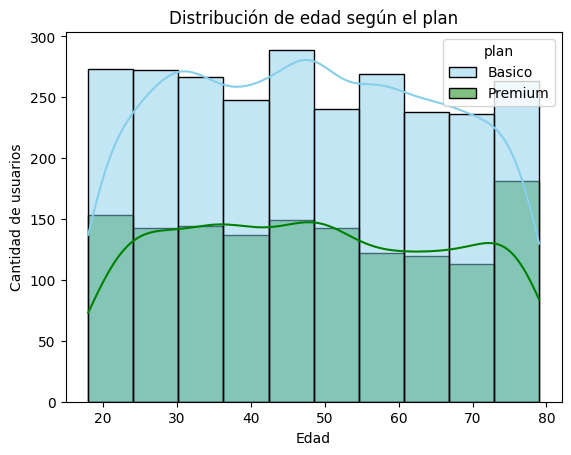

In [30]:
# Histograma para visualizar la edad (age)

import seaborn as sns
sns.histplot( data=user_profile, x='age', hue='plan', bins=10, palette=['skyblue','green'], kde=True)
mpp.title('Distribución de edad según el plan')
mpp.xlabel('Edad')
mpp.ylabel('Cantidad de usuarios')
mpp.show()


💡Insights: 
- Distribución esta bastante pareja no hay un grupo de edad que domine. El plan Básico tiene casi el doble de usuarios que Premium en cada rango de edad, el plan básico es casi plano y tiene un pico pequeño alrededor de los 40 a 50 años. Premium también es bastante estable, con una baja entre los 50 y 75 años y un aumento claro en el último rango. La edad no parece cambiar mucho qué plan se elige. La única diferencia notable es que los usuarios mayores eligen Premium con algo más de frecuencia.

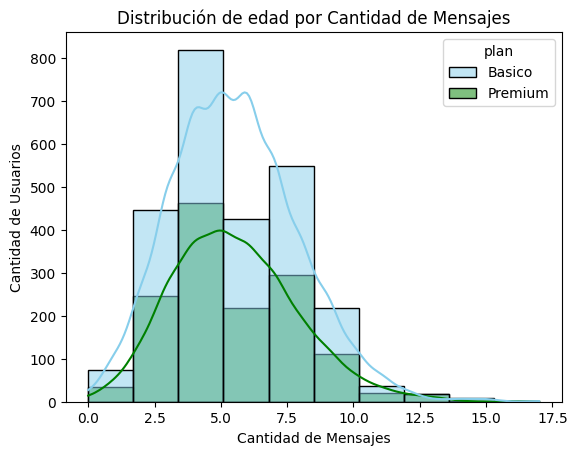

In [31]:

# Histograma para visualizar la cant_mensajes
sns.histplot( data=user_profile, x='cant_mensajes', hue='plan', bins=10, palette=['skyblue','green'], kde=True)
mpp.title('Distribución de edad por Cantidad de Mensajes')
mpp.xlabel('Cantidad de Mensajes')
mpp.ylabel('Cantidad de Usuarios')
mpp.show()



💡Insights: 
- La mayor parte de los usuarios envía entre 2 y 8 mensajes, y el valor más común está alrededor de 4 a 5 para ambos planes, es el pico de las dos curvas. La distribución tiene un sesgo a la derecha, muy pocos usuarios pasan de 10 mensajes y casi nadie llega despues de los 15 mensajes. Ambos planes tienen casi la misma forma. Las dos curvas alcanzan su punto máximo cerca del 5. El plan no parece influir en cuántos mensajes envía un usuario

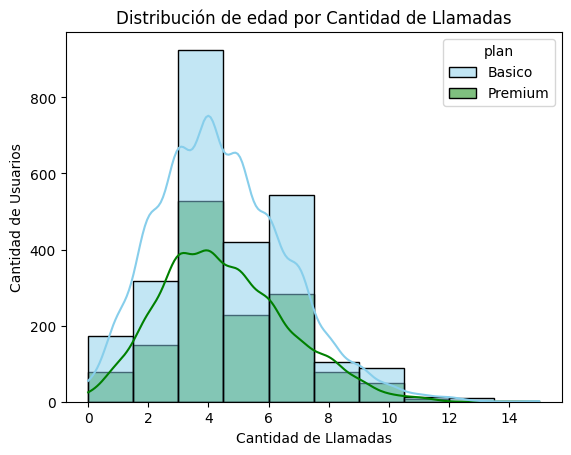

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot( data=user_profile, x='cant_llamadas', hue='plan', bins=10, palette=['skyblue','green'], kde=True)
mpp.title('Distribución de edad por Cantidad de Llamadas')
mpp.xlabel('Cantidad de Llamadas')
mpp.ylabel('Cantidad de Usuarios')
mpp.show()

💡Insights: 
- Distribución es muy similar al grafico anterior de los mensajes. La mayoría de los usuarios hace entre 2 y 7 llamadas, y lo más común es alrededor de 3 a 5, donde está el pico de las dos curvas, el sesgo esta a la derecha. El plan básico y premium tienen un comportamiento muy parecido. El tipo de plan no parece influir en la cantidad de llamadas.

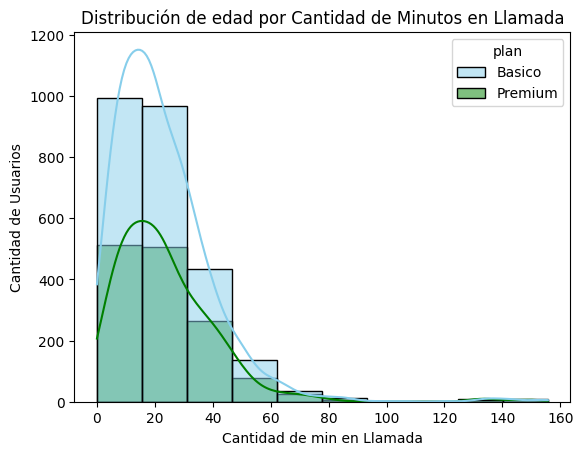

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot( data=user_profile, x='cant_minutos_llamada', hue='plan', bins=10, palette=['skyblue','green'], kde=True)
mpp.title('Distribución de edad por Cantidad de Minutos en Llamada')
mpp.xlabel('Cantidad de min en Llamada')
mpp.ylabel('Cantidad de Usuarios')
mpp.show()

💡Insights: 
- La mayoría de los usuarios usa entre 0 y 30 minutos, tiene un sesgo a la derecha, la forma es similar en los dos planes, ambos alcanza su pico máximo en 15 minutos. Premium tiene proporcionalmente más usuarios en los rangos altos. Hay unos pocos usuarios entre 125 y 156 minutos, separados del resto por un hueco de 95 a 125 en el que no hay nadie. Los usuarios hacen en general llamadas cortas que no pasan de los 30 min. El plan Premium tiene una ligera tendencia a un mayor consumo de minutos, a diferencia de llamadas y mensajes, donde no se notaba diferencia.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

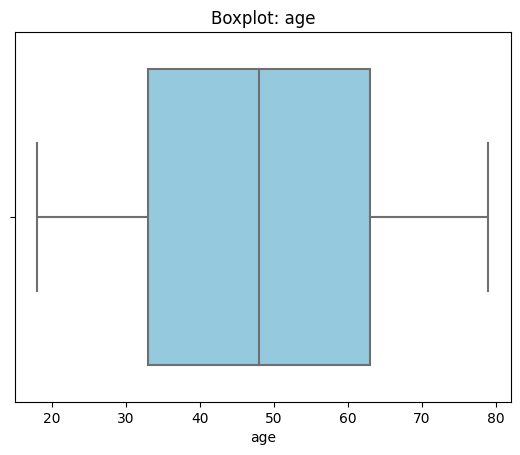

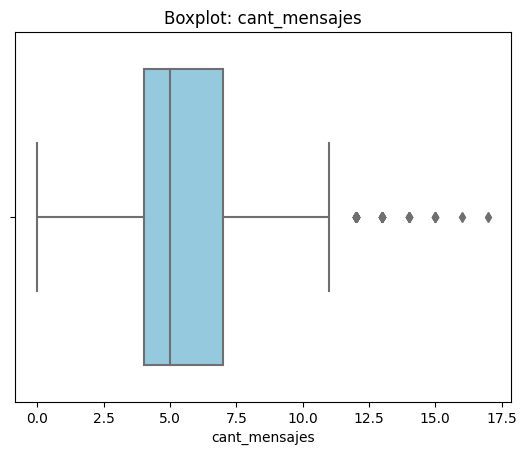

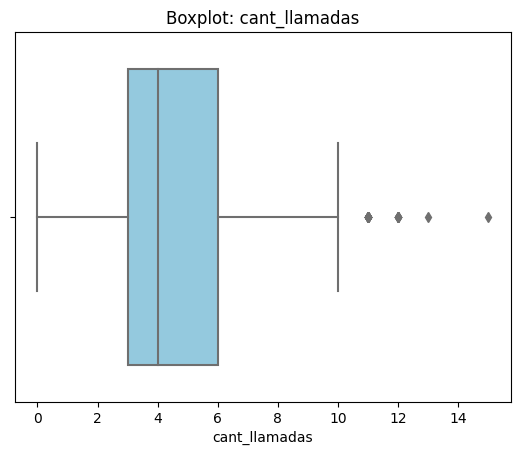

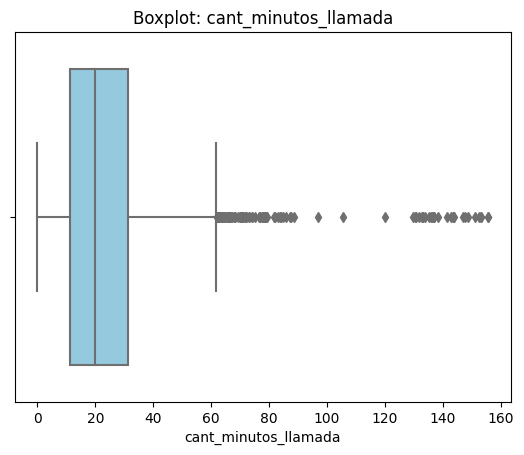

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    mpp.title(f'Boxplot: {col}')
    mpp.xlabel(col)
    mpp.show()

💡Insights: 
- Age: No presenta outliers.
- cant_mensajes: Existen outliers.
- cant_llamadas: Existen outliers.
- cant_minutos_llamada: Existen outliers.

In [35]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1= user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    outliers = user_profile[(user_profile[col] > limite_superior)]
    print(f'Límite superior: {limite_superior:.2f}')
    print(f'Valores atípicos: {len(outliers)}\n')


Límite superior: 11.50
Valores atípicos: 46

Límite superior: 10.50
Valores atípicos: 30

Límite superior: 61.86
Valores atípicos: 109



In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: Mantener los outliers, porque el límite superior es 11.5 y el máximo es 17. Los 46 atípicos son solo el 1.2% de los 3,999 usuarios. Enviar 12 a 17 mensajes es perfectamente posible: no son errores de captura, sino usuarios que mandan más mensajes que el promedio. La media y la mediana casi no difieren, así que estos valores no distorsionan el análisis.
- cant_llamadas: Mantener los outliers, porque el límite superior es 10.5 y el máximo es 15. Son apenas 30 atípicos. Hacer 11 a 15 llamadas es un comportamiento normal en un usuario, no un dato imposible. La media y la mediana casi no difieren, así que estos valores no distorsionan el análisis.
- cant_minutos_llamada: Mantener los outliers si se ve complicado ya que su límite superior es 61.86 y el máximo es 155.69, con 109 atípicos (2.7%). Es la variable con más outliers y  la media es mayor que la mediana. Aun así, conviene mantenerlos por que Hablar 60 a 155 minutos es un consumo posible, no un dato imposible.
Son justo los usuarios de mayor consumo, y en el histograma se vio que Premium tiene proporcionalmente más usuarios en esos rangos. Eliminarlos borraría la principal diferencia entre los planes.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso
def classify_segment(row):
    texto = row['cant_mensajes']
    llamada = row['cant_llamadas']

    if llamada < 5 and texto < 5:
        return 'Bajo uso'
    elif llamada < 10 and texto < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'


user_profile['grupo_uso'] = user_profile.apply(classify_segment, axis=1)


In [38]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad
def classify_segment(row):
    edad = row['age']

    if edad < 30:
        return 'Joven'
    elif edad < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'


user_profile['grupo_edad'] = user_profile.apply(classify_segment, axis=1)


In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

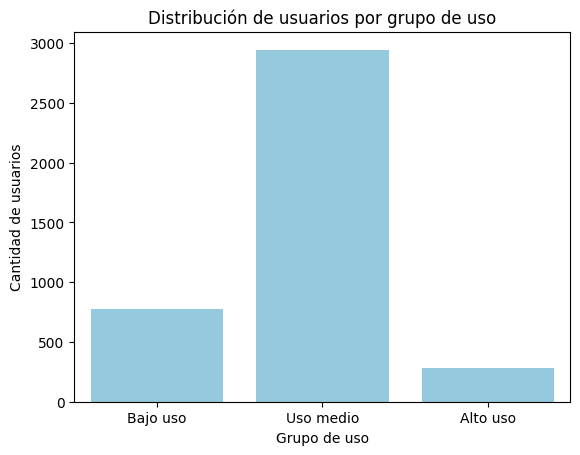

In [41]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso',
              order=['Bajo uso', 'Uso medio', 'Alto uso'], color='skyblue')
mpp.title('Distribución de usuarios por grupo de uso')
mpp.xlabel('Grupo de uso')
mpp.ylabel('Cantidad de usuarios')
mpp.show()

mpp.show()

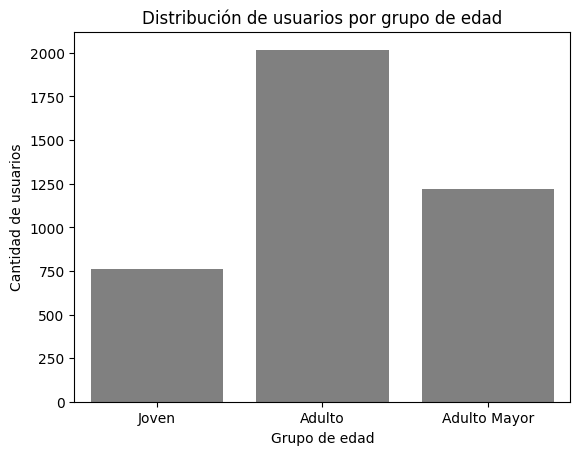

In [43]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad',
              order=['Joven', 'Adulto', 'Adulto Mayor'], color='Grey')
mpp.title('Distribución de usuarios por grupo de edad')
mpp.xlabel('Grupo de edad')
mpp.ylabel('Cantidad de usuarios')
mpp.show()

mpp.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
Dataset	Columna	Problema	Magnitud	Acción
users	age	Sentinel -999	55 filas (1.4%)	Reemplazado por la mediana (48)
users	city	Nulos	469 filas (11.7%)	Se dejan como nulos
users	reg_date	Fechas imposibles (año 2026)	40 filas (1%)	Marcadas como NaT
users	churn_date	Nulos	3,534 filas (88.4%)	No es un error: son clientes activos. Solo 466 (11.7%) cancelaron.
usage	date	Nulos	50 filas (0.125%)	Se dejan como nulos
usage	duration / length	Nulos	55.2% / 44.7%	Son MAR: dependen de type (los mensajes no tienen duración y las llamadas no tienen longitud). Se dejan como nulos.



🔍 **Segmentos por Edad**
- Adulto es el segmento más grande. No es porque haya más personas de cada edad, sino porque abarca más años (30). Además incluye los 55 registros cuya edad se reemplazó por la mediana (48). Las edades se reparten de forma pareja: ningún rango de edad predomina.
La edad casi no cambia la elección del plan: en todos los segmentos Básico tiene más o menos el doble de usuarios que Premium. La excepción son los Adultos Mayores de más de 73 años, que eligen Premium con más frecuencia. Es el único patrón de edad destacable.
En cantidad de mensajes y llamadas no se observan diferencias claras entre segmentos de edad.


📊 **Segmentos por Nivel de Uso**
- Uso medio es el segmento dominante. El usuario típico envía 5 mensajes, hace 4 llamadas y habla unos 20 minutos (medianas).
- Bajo uso es un grupo importante de clientes que casi no usan el servicio. Es el más expuesto a cancelar, porque paga por paquetes que no aprovecha.
- Alto uso es una minoría pequeña e intensiva. Ahí se concentran los outliers: hasta 17 mensajes, 15 llamadas y 155 minutos.
Por plan: en número de mensajes y llamadas, Básico y Premium se comportan prácticamente igual. La diferencia está en los minutos, Premium tiene proporcionalmente más usuarios que hablan más de 30 minutos.


➡️ Esto sugiere que el valor de los clientes de ConnectaTel no depende de su edad ni de cuántas veces usan el servicio, sino de cuánto tiempo hablan. El plan Premium no atrae a usuarios que llaman o escriben más, sino a los que hacen llamadas más largas. Además, la mayoría de los clientes usa una fracción muy pequeña de lo que incluye su plan (unos 5 de 100 mensajes y unos 20 de 100 minutos en Básico, y mucho menos de los 500 mensajes y 600 minutos de Premium). Es decir, los planes actuales están sobredimensionados respecto al consumo real


💡 **Recomendaciones**
- Los paquetes están sobredimensionados. El usuario típico usa 5 de 100 mensajes y unos 20 de 100 minutos en Básico. En Premium usa una fracción mínima de sus 500 mensajes y 600 minutos. Los clientes pagan por capacidad que no aprovechan, y eso es un riesgo de cancelación. Crear un plan de entrada, más barato que Básico (por ejemplo, 30 minutos y 20 mensajes), para el segmento de Bajo uso. Ayuda a retener clientes sensibles al precio y a atraer nuevos.
Rediseñar Premium alrededor de lo que más diferencia a sus usuarios: los minutos. Por ejemplo, un plan intermedio de unos 200 minutos, y agregar beneficios (más GB, llamadas internacionales) en lugar de mensajes que no se usan.
Ofertas para Adultos Mayores centradas en llamadas (minutos ilimitados a números frecuentes, atención preferente), ya que es el grupo que más se inclina por Premium.
Mejorar la calidad de los datos: validar edad y fecha de registro al capturar, evitar valores como "?" en ciudad y registrar el consumo de datos (GB). El plan cobra por GB, pero usage no tiene esa información, así que no se pudo evaluar la parte del plan que probablemente más pesa en el precio.


---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`